# Examining Sub-Research Research Question 3: Date Published

The third sub-research question is as follows: **'Are there differences in content between homosexual and heterosexual fan fiction on Archive of Our Own, regarding variables such as the language, date published, or word count?**

In [1]:
# Import package
import polars as pl
import pyarrow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date

In [2]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [3]:
df_metadata = df_metadata.with_columns(pl.col("published").str.slice(0, 4).cast(pl.Int32).alias("Year")) # Turn the metadata publishing date into publishing year

In [122]:
# Calculate the year frequencies
ff_mm_year_amt = df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")
).select(pl.col("Year").value_counts()).unnest("Year").sort("count", descending=True)
fm_year_amt = df_metadata.filter(
    (pl.col("Category") == "F/M")
).select(pl.col("Year").value_counts()).unnest("Year").sort("count", descending=True)

print("Homosexual Fan Works per Year:")
ff_mm_year_amt.show(13) # Filtered by F/F + M/M
print("Heterosexual Fan Works per Year:")
fm_year_amt.show(11) # Filtered by F/M

# Turn the languages into lists
ff_mm_year_list = ff_mm_year_amt.to_series(0).to_list()
fm_year_list = fm_year_amt.to_series(0).to_list()

print("Homosexual Years: ", ff_mm_year_list)
print("Heterosexual Years: ", fm_year_list)

Homosexual Fan Works per Year:


Year,count
i32,u32
2023,1776
2024,1152
2018,1126
2017,580
2016,466
2022,243
2019,182
2025,176
2008,8


Heterosexual Fan Works per Year:


Year,count
i32,u32
2024,1315
2023,1167
2017,610
2016,556
2018,337
2025,170
2019,52
2022,43
2015,4


Homosexual Years:  [2023, 2024, 2018, 2017, 2016, 2022, 2019, 2025, 2008, 2007, 2015, 2020, 2013]
Heterosexual Years:  [2024, 2023, 2017, 2016, 2018, 2025, 2019, 2022, 2015, 2013, 2020]


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [103]:
# Filtered by F/F + M/M based on year
df_ff_mm_years_ratings = pl.DataFrame()
for ff_mm_year in ff_mm_year_list:
    ff_mm_year_ratings = df_metadata.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Year") == ff_mm_year)
    ).select(pl.col("Rating").value_counts()).unnest("Rating").sort("Rating").unpivot(index="Rating", variable_name="count").pivot("Rating", index="count").drop("count").with_columns(pl.lit(ff_mm_year).alias("Year")) # Filter based on year
    df_ff_mm_years_ratings = pl.concat([df_ff_mm_years_ratings, ff_mm_year_ratings], how="diagonal") # Concatenate the DataFrames

df_ff_mm_years_ratings = df_ff_mm_years_ratings.select(['Year', 'Not Rated', 'General Audiences', 'Teen And Up Audiences', 'Mature', 'Explicit']) # Reorder the columns
df_ff_mm_years_ratings = df_ff_mm_years_ratings.with_columns(pl.all().fill_null(strategy="zero"))

# Filtered by F/M based on year
df_fm_years_ratings = pl.DataFrame()
for fm_year in fm_year_list:
    fm_year_ratings = df_metadata.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Year") == fm_year)
    ).select(pl.col("Rating").value_counts()).unnest("Rating").sort("Rating").unpivot(index="Rating", variable_name="count").pivot("Rating", index="count").drop("count").with_columns(pl.lit(fm_year).alias("Year")) # Filter based on year
    df_fm_years_ratings = pl.concat([df_fm_years_ratings, fm_year_ratings], how="diagonal") # Concatenate the DataFrames

df_fm_years_ratings = df_fm_years_ratings.select(['Year', 'Not Rated', 'General Audiences', 'Teen And Up Audiences', 'Mature', 'Explicit']) # Reorder the columns
df_fm_years_ratings = df_fm_years_ratings.with_columns(pl.all().fill_null(strategy="zero"))

print("Homosexual Year Ratings Amount:")
df_ff_mm_years_ratings.show(500)
print("Heterosexual Year Ratings Amount:")
df_fm_years_ratings.show(500)

# Calculate the Ratings percentage distribution per year
# Filtered by F/F + M/M
df_ff_mm_years_percentages_ratings = df_ff_mm_years_ratings.with_columns(
    (pl.col("Not Rated") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Not Rated"), (pl.col("General Audiences") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("General Audiences"), (pl.col("Teen And Up Audiences") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Teen And Up Audiences"), (pl.col("Mature") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Mature"), (pl.col("Explicit") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Explicit")
).with_columns(pl.exclude("Year")).sort("Year")

# Filtered by F/M
df_fm_years_percentages_ratings = df_fm_years_ratings.with_columns(
     (pl.col("Not Rated") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Not Rated"), (pl.col("General Audiences") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("General Audiences"), (pl.col("Teen And Up Audiences") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Teen And Up Audiences"), (pl.col("Mature") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Mature"), (pl.col("Explicit") / pl.sum_horizontal(pl.exclude("Year")) * 100).alias("Explicit")
).with_columns(pl.exclude("Year")).sort("Year")

print("Homosexual Year Ratings Percentage Distribution:")
df_ff_mm_years_percentages_ratings.show(500)
print("Heterosexual Year Ratings Percentage Distribution:")
df_fm_years_percentages_ratings.show(500)

Homosexual Year Ratings Amount:


Year,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
i32,u32,u32,u32,u32,u32
2023,175,295,431,270,605
2024,93,303,313,192,251
2018,145,324,398,136,123
2017,36,154,250,82,58
2016,35,116,181,75,59
2022,40,65,84,32,22
2019,15,42,73,21,31
2025,13,55,52,31,25
2008,0,6,2,0,0


Heterosexual Year Ratings Amount:


Year,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
i32,u32,u32,u32,u32,u32
2024,98,331,347,235,304
2023,86,235,216,216,414
2017,95,255,207,40,13
2016,60,203,219,48,26
2018,19,123,137,36,22
2025,17,32,48,42,31
2019,4,14,26,3,5
2022,9,12,17,2,3
2015,1,1,2,0,0


Homosexual Year Ratings Percentage Distribution:


Year,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
i32,f64,f64,f64,f64,f64
2007,0.0,0.0,100.0,0.0,0.0
2008,0.0,75.0,25.0,0.0,0.0
2013,0.0,0.0,0.0,0.0,100.0
2015,0.0,100.0,0.0,0.0,0.0
2016,7.51073,24.892704,38.841202,16.094421,12.660944
2017,6.206897,26.551724,43.103448,14.137931,10.0
2018,12.877442,28.774423,35.346359,12.078153,10.923623
2019,8.241758,23.076923,40.10989,11.538462,17.032967
2020,0.0,100.0,0.0,0.0,0.0


Heterosexual Year Ratings Percentage Distribution:


Year,Not Rated,General Audiences,Teen And Up Audiences,Mature,Explicit
i32,f64,f64,f64,f64,f64
2013,0.0,100.0,0.0,0.0,0.0
2015,25.0,25.0,50.0,0.0,0.0
2016,10.791367,36.510791,39.388489,8.633094,4.676259
2017,15.57377,41.803279,33.934426,6.557377,2.131148
2018,5.637982,36.498516,40.652819,10.682493,6.52819
2019,7.692308,26.923077,50.0,5.769231,9.615385
2020,100.0,0.0,0.0,0.0,0.0
2022,20.930233,27.906977,39.534884,4.651163,6.976744
2023,7.369323,20.137104,18.508997,18.508997,35.475578


### 1.2 Visualizing the Ratings Datasets

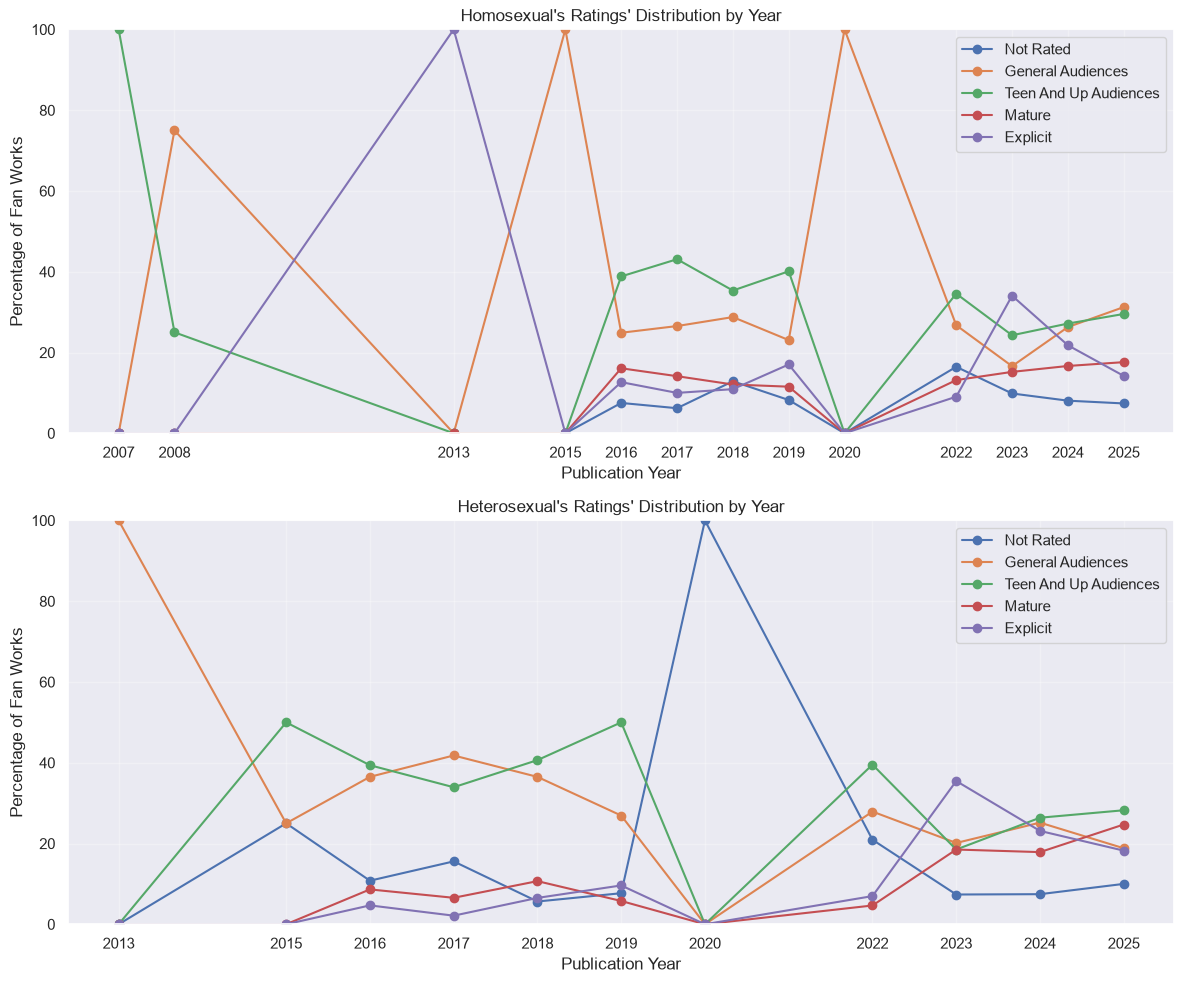

In [102]:
fig, ax = plt.subplots(2, 1, figsize=(12, 10)) # Set figure size

# Filtered by F/F + M/M
ff_mm_years = df_ff_mm_years_percentages_ratings["Year"].to_numpy()

# Plot a line plot
ax[0].plot(ff_mm_years, df_ff_mm_years_percentages_ratings["Not Rated"].to_numpy(), marker="o", label="Not Rated")
ax[0].plot(ff_mm_years, df_ff_mm_years_percentages_ratings["General Audiences"].to_numpy(), marker="o", label="General Audiences")
ax[0].plot(ff_mm_years, df_ff_mm_years_percentages_ratings["Teen And Up Audiences"].to_numpy(), marker="o", label="Teen And Up Audiences")
ax[0].plot(ff_mm_years, df_ff_mm_years_percentages_ratings["Mature"].to_numpy(), marker="o", label="Mature")
ax[0].plot(ff_mm_years, df_ff_mm_years_percentages_ratings["Explicit"].to_numpy(), marker="o", label="Explicit")

ax[0].set_title("Homosexual's Ratings' Distribution by Year")
ax[0].set_xlabel("Publication Year")
ax[0].set_ylabel("Percentage of Fan Works")

ax[0].set_ylim(0, 100)
ax[0].set_xticks(ff_mm_years)
ax[0].legend()
ax[0].grid(alpha=0.3)

# Filtered by F/M
fm_years = df_fm_years_percentages_ratings["Year"].to_numpy()

# Plot a line plot
ax[1].plot(fm_years, df_fm_years_percentages_ratings["Not Rated"].to_numpy(), marker="o", label="Not Rated")
ax[1].plot(fm_years, df_fm_years_percentages_ratings["General Audiences"].to_numpy(), marker="o", label="General Audiences")
ax[1].plot(fm_years, df_fm_years_percentages_ratings["Teen And Up Audiences"].to_numpy(), marker="o", label="Teen And Up Audiences")
ax[1].plot(fm_years, df_fm_years_percentages_ratings["Mature"].to_numpy(), marker="o", label="Mature")
ax[1].plot(fm_years, df_fm_years_percentages_ratings["Explicit"].to_numpy(), marker="o", label="Explicit")

ax[1].set_title("Heterosexual's Ratings' Distribution by Year")
ax[1].set_xlabel("Publication Year")
ax[1].set_ylabel("Percentage of Fan Works")

ax[1].set_ylim(0, 100)
ax[1].set_xticks(fm_years)
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [109]:
df_ff_mm_year_archive_warnings = (df_metadata.filter(
    (pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")).group_by(["Year", "Archive Warning"]).agg(pl.len().alias("Frequency")).with_columns((pl.col("Frequency") / pl.col("Frequency").sum().over("Year") * 100).alias("Percentage"))) # Filtered by F/F + M/M

df_fm_year_archive_warnings = (df_metadata.filter(
    (pl.col("Category") == "F/M")).group_by(["Year", "Archive Warning"]).agg(pl.len().alias("Frequency")).with_columns((pl.col("Frequency") / pl.col("Frequency").sum().over("Year") * 100).alias("Percentage"))) # Filtered by F/M

print("Homosexual Year Archive Warnings' Frequency and Percentage Distribution:")
df_ff_mm_year_archive_warnings.show(46)
print("Heterosexual Year Archive Warnings' Frequency and Percentage Distribution:")
df_fm_year_archive_warnings.show(45)

df_ff_mm_year_percentages_aw = (df_ff_mm_year_archive_warnings.pivot(on="Archive Warning", index="Year", values="Percentage").sort("Year").fill_null(strategy="zero").drop("null")) # Pivot the table
df_fm_year_percentages_aw = (df_fm_year_archive_warnings.pivot(on="Archive Warning", index="Year", values="Percentage").sort("Year").fill_null(strategy="zero").drop("null")) # Pivot the table

print("Homosexual Year Archive Warnings' Percentage Distribution:")
df_ff_mm_year_percentages_aw.show(100)
print("Heterosexual Year Archive Warnings' Percentage Distribution:")
df_fm_year_percentages_aw.show(100)

Homosexual Year Archive Warnings' Frequency and Percentage Distribution:


Year,Archive Warning,Frequency,Percentage
i32,str,u32,f64
2016,null,11,2.360515
2025,"""Underage Sex""",4,2.272727
2016,"""Major Character Death""",13,2.7897
2025,"""Graphic Depictions Of Violence""",8,4.545455
2016,"""No Archive Warnings Apply""",296,63.519313
2016,"""Graphic Depictions Of Violence""",9,1.93133
2019,null,5,2.747253
2016,"""Rape/Non-Con""",2,0.429185
2018,null,21,1.865009


Heterosexual Year Archive Warnings' Frequency and Percentage Distribution:


Year,Archive Warning,Frequency,Percentage
i32,str,u32,f64
2016,"""No Archive Warnings Apply""",405,72.841727
2018,"""Major Character Death""",8,2.373887
2018,"""Graphic Depictions Of Violence""",1,0.296736
2019,"""Graphic Depictions Of Violence""",1,1.923077
2022,"""No Archive Warnings Apply""",28,65.116279
2016,"""Graphic Depictions Of Violence""",3,0.539568
2024,"""Major Character Death""",24,1.825095
2013,"""No Archive Warnings Apply""",1,100.0
2024,"""Creator Chose Not To Use Archi…",440,33.460076


Homosexual Year Archive Warnings' Percentage Distribution:


Year,Underage Sex,Major Character Death,Graphic Depictions Of Violence,No Archive Warnings Apply,Rape/Non-Con,Creator Chose Not To Use Archive Warnings
i32,f64,f64,f64,f64,f64,f64
2007,0.0,0.0,0.0,100.0,0.0,0.0
2008,0.0,0.0,0.0,100.0,0.0,0.0
2013,0.0,0.0,0.0,0.0,0.0,100.0
2015,0.0,0.0,0.0,100.0,0.0,0.0
2016,0.214592,2.7897,1.93133,63.519313,0.429185,28.755365
2017,0.344828,1.896552,3.103448,68.793103,0.862069,22.931034
2018,0.0,1.598579,1.953819,61.722913,0.35524,32.50444
2019,0.0,2.197802,1.648352,62.087912,0.549451,30.769231
2020,0.0,0.0,0.0,100.0,0.0,0.0


Heterosexual Year Archive Warnings' Percentage Distribution:


Year,No Archive Warnings Apply,Major Character Death,Graphic Depictions Of Violence,Creator Chose Not To Use Archive Warnings,Rape/Non-Con,Underage Sex
i32,f64,f64,f64,f64,f64,f64
2013,100.0,0.0,0.0,0.0,0.0,0.0
2015,25.0,0.0,0.0,75.0,0.0,0.0
2016,72.841727,3.776978,0.539568,19.964029,0.179856,0.0
2017,70.163934,2.295082,0.327869,22.95082,0.163934,0.0
2018,71.810089,2.373887,0.296736,22.255193,0.0,0.0
2019,69.230769,0.0,1.923077,25.0,0.0,0.0
2020,0.0,0.0,0.0,100.0,0.0,0.0
2022,65.116279,0.0,2.325581,32.55814,0.0,0.0
2023,42.159383,2.570694,6.083976,29.391602,2.570694,7.455013


### 2.2 Visualizing the Archive Warnings Datasets

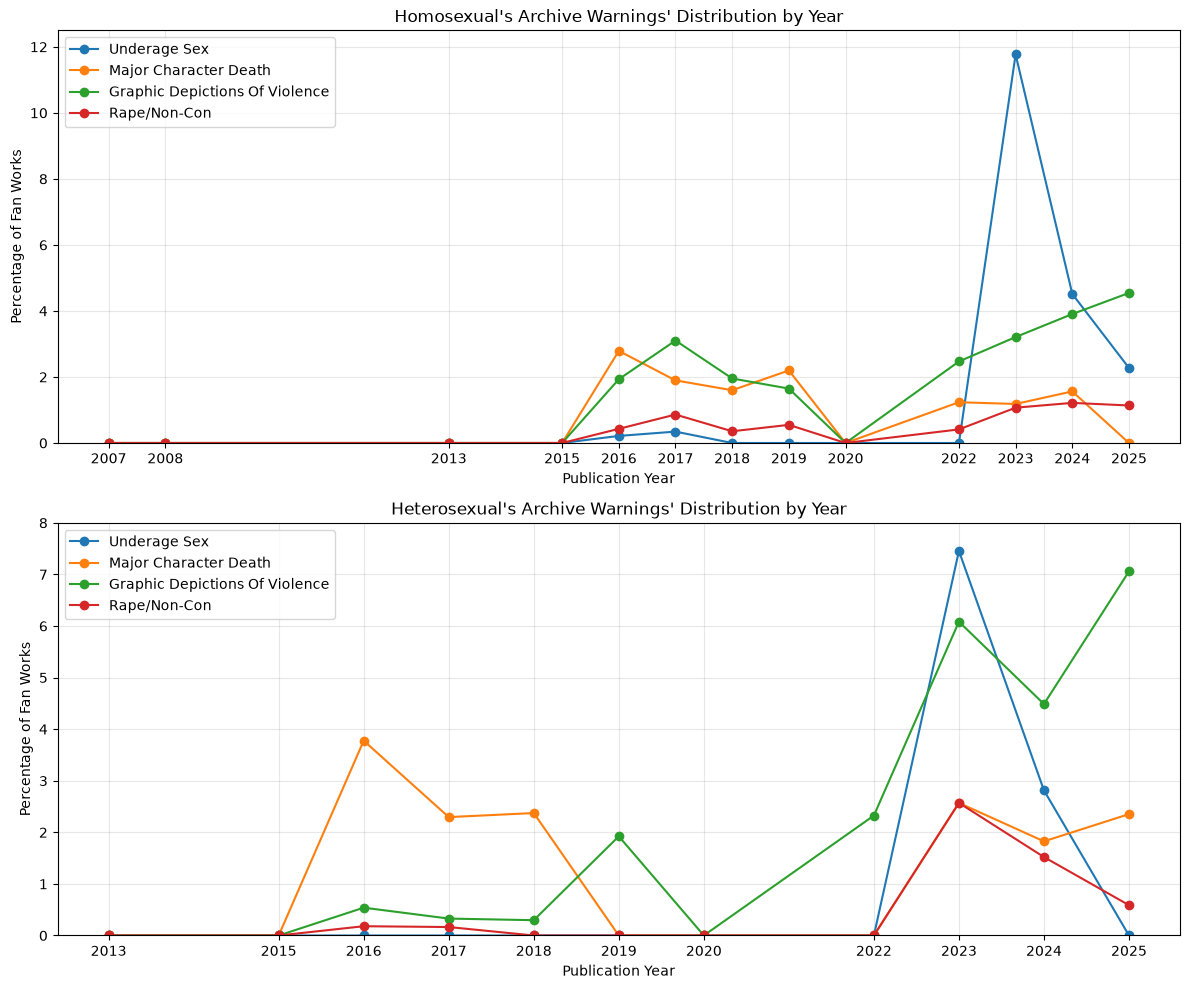

In [115]:
fig, ax = plt.subplots(2, 1, figsize=(12, 10)) # Set figure size

# Filtered by F/F + M/M
ff_mm_years = df_ff_mm_year_percentages_aw["Year"].to_numpy()

# Plot a line plot
ax[0].plot(ff_mm_years, df_ff_mm_year_percentages_aw["Underage Sex"].to_numpy(), marker="o", label="Underage Sex")
ax[0].plot(ff_mm_years, df_ff_mm_year_percentages_aw["Major Character Death"].to_numpy(), marker="o", label="Major Character Death")
ax[0].plot(ff_mm_years, df_ff_mm_year_percentages_aw["Graphic Depictions Of Violence"].to_numpy(), marker="o", label="Graphic Depictions Of Violence")
ax[0].plot(ff_mm_years, df_ff_mm_year_percentages_aw["Rape/Non-Con"].to_numpy(), marker="o", label="Rape/Non-Con")

ax[0].set_title("Homosexual's Archive Warnings' Distribution by Year")
ax[0].set_xlabel("Publication Year")
ax[0].set_ylabel("Percentage of Fan Works")

ax[0].set_ylim(0, 12.5)
ax[0].set_xticks(ff_mm_years)
ax[0].legend()
ax[0].grid(alpha=0.3)

# Filtered by F/M
fm_years = df_fm_year_percentages_aw["Year"].to_numpy()

# Plot a line plot
ax[1].plot(fm_years, df_fm_year_percentages_aw["Underage Sex"].to_numpy(), marker="o", label="Underage Sex")
ax[1].plot(fm_years, df_fm_year_percentages_aw["Major Character Death"].to_numpy(), marker="o", label="Major Character Death")
ax[1].plot(fm_years, df_fm_year_percentages_aw["Graphic Depictions Of Violence"].to_numpy(), marker="o", label="Graphic Depictions Of Violence")
ax[1].plot(fm_years, df_fm_year_percentages_aw["Rape/Non-Con"].to_numpy(), marker="o", label="Rape/Non-Con")

ax[1].set_title("Heterosexual's Archive Warnings' Distribution by Year")
ax[1].set_xlabel("Publication Year")
ax[1].set_ylabel("Percentage of Fan Works")

ax[1].set_ylim(0, 8)
ax[1].set_xticks(fm_years)
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Datasets

In [104]:
fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]
categories = ["F/F", "M/M", "F/M"]

In [106]:
def create_temp_df(fandom, category, year):
    """
    Creates a DataFrame of the additional tags frequencies.

    Parameters:
        fandom (string): Target fandom.
        category (string): Target relationship category.
    returns:
        df_temp (DataFrame): Consisting of Fandom, Category, Additional Tags, and Freq columns.
    """
    # Filter the df_cats_and_fandoms DataFrame based on the target fandom and category
    df_filtered = df_metadata.filter(
        (pl.col("Fandom") == fandom) &
        (pl.col("Category") == category) &
        (pl.col("Year") == year)
        
    ).with_row_index()

    # Convert the Additional Tags column from a string to a list of strings
    df_filtered = df_filtered.with_columns(
        pl.col("Additional Tags").str.split(", "),
    )
    
    tags_freq = {}
    for row in df_filtered.iter_rows(named=True):
        try:
            for tag in row["Additional Tags"]:
                # Check if the Additional Tags key exists
                if tag not in tags_freq:
                    # Create the Additional Tags key
                    tags_freq[tag] = 0
                # Increase the Additional Tags frequency count with 1
                tags_freq[tag] += 1
        except:
            pass

    # Sort the tags_freq dictionary based on descending additional tag frequency order
    tags_freq = dict(sorted(tags_freq.items(), key=lambda item: item[1], reverse=True))

    # Create a DataFrame
    df_temp = pl.DataFrame({
        "Fandom": fandom,
        "Category": category,
        "Year": year,
        "Additional Tags": tags_freq.keys(),
        "Freq": tags_freq.values()
    })

    return df_temp

In [107]:
# Combine the language lists
years = ff_mm_year_list + list(set(fm_year_list) - set(ff_mm_year_list))
years

[2023, 2024, 2018, 2017, 2016, 2022, 2019, 2025, 2008, 2013, 2020, 2015, 2007]

In [108]:
# Calculate the additional tags frequency based on language
df_main = pl.DataFrame()
for fandom in fandoms:
    for category in categories:
        for year in years:
            # Concatenate the temporary DataFrame to df_main
            df_main = pl.concat([df_main, create_temp_df(fandom, category, year)])

df_main

Fandom,Category,Year,Additional Tags,Freq
str,str,i32,str,i64
"""DC's Legends of Tomorrow (TV)""","""F/F""",2023,"""Fluff""",19
"""DC's Legends of Tomorrow (TV)""","""F/F""",2023,"""Angst with a Happy Ending""",12
"""DC's Legends of Tomorrow (TV)""","""F/F""",2023,"""Hurt/Comfort""",12
"""DC's Legends of Tomorrow (TV)""","""F/F""",2023,"""Love""",10
"""DC's Legends of Tomorrow (TV)""","""F/F""",2023,"""Fluff and Angst""",7
…,…,…,…,…
"""Spider-Man: Spider-Verse (Sony…","""F/M""",2025,"""texting while fighting""",1
"""Spider-Man: Spider-Verse (Sony…","""F/M""",2025,"""y/n lives off school campus""",1
"""Spider-Man: Spider-Verse (Sony…","""F/M""",2025,"""No beta we die like uncle Aaro…",1


In [109]:
df_annotated_tags = pl.read_csv("./data/df_additional_tag_annotations.csv") # Read the CSV file
df_add_tag_annotation = pl.read_csv("./data/df_additional_tag_annotations.csv")

# Concatenate the DataFrames
df_annotated_additional_tags = pl.concat([df_main, df_annotated_tags], how="align")
df_annotated_additional_tags

Fandom,Category,Year,Additional Tags,Freq,Character,Narrative,Porn,Kink
str,str,i32,str,i64,str,str,str,str
"""Avatar: The Last Airbender (Ca…","""F/M""",2024,"""!!TW!!""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""",2024,"""""Has she always been good at t…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""",2023,"""""I love the smell of incest 😍😍…",1,"""No Character""","""No Narrative""","""Is Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""",2024,"""""I loved her to the point of i…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""DC's Legends of Tomorrow (TV)""","""F/F""",2022,"""""Mayday Mayday!""""",1,"""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""
…,…,…,…,…,…,…,…,…
"""Spider-Man: Spider-Verse (Sony…","""M/M""",2023,"""鱼哭了海知道狗哭了谁知道""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""",2023,"""🍆💦""",2,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""",2024,"""🍆💦""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""


In [110]:
def label_freq(df):
    """
    Calculates the frequency of the annotations.

    Parameter:
        df (DataFrame): Filtered DataFrame.
    Returns:
        df_label_freq (DataFrame): Contains the frequency of the annotations.
    """
    # Add the frequency of the annotations based on unique additional tags
    categories = ["Character", "Narrative", "Porn", "Kink"]

    df_unique_values = pl.DataFrame()
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[0]).value_counts()).unnest(categories[0]).rename({"Character": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[1]).value_counts()).unnest(categories[1]).rename({"Narrative": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[2]).value_counts()).unnest(categories[2]).rename({"Porn": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[3]).value_counts()).unnest(categories[3]).rename({"Kink": "Label"})])
    df_unique_values = df_unique_values.rename({"count": "Unique Additional Tags Frequency"})

    # Turn into lists
    char_list = ['No Character', 'Biography', 'Physical Feature', 'Emotion/Mental State', 'Relationship', "Personality"]
    nar_list = ['No Narrative', 'Plot', 'Event-related/Action', 'Theme/Genre', 'WorldSetting', 'Narrative Methods', 'Format']
    porn_list = ['Not Porn', 'Is Porn']
    kink_list = ['Not Kink', 'Is Kink']

    # Append the frequency of the annotations based on total additional tags
    df_freq_count = pl.DataFrame()
    for char_label in char_list:
        df_temp_char = pl.DataFrame({
            "Label": char_label,
            "Freq": df.filter(pl.col("Character") == char_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_char])
    for nar_label in nar_list:
        df_temp_nar = pl.DataFrame({
            "Label": nar_label,
            "Freq": df.filter(pl.col("Narrative") == nar_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_nar])
    for porn_label in porn_list:
        df_temp_porn = pl.DataFrame({
            "Label": porn_label,
            "Freq": df.filter(pl.col("Porn") == porn_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_porn])
    for kink_label in kink_list:
        df_temp_kink = pl.DataFrame({
            "Label": kink_label,
            "Freq": df.filter(pl.col("Kink") == kink_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_kink])
    
    df_freq_count = df_freq_count.rename({"Freq": "Total Additional Tags Frequency"})

    labels = df_freq_count.to_series(0)
    df_label_freq = pl.concat([df_unique_values, df_freq_count], how='align')
    df_label_freq = df_label_freq.sort(pl.col("Total Additional Tags Frequency"), descending=True)
    
    return df_label_freq

In [111]:
character_labels = ["No Character", "Biography", "Physical Feature", "Emotion/Mental State", "Relationship", "Personality"]
narrative_labels = ["No Narrative", "Plot", "Event-related/Action", "Theme/Genre", "WorldSetting", "Narrative Methods", "Format"]
porn_labels = ["Not Porn", "Is Porn"]
kink_labels = ["Not Kink", "Is Kink"]

In [133]:
# Filtered by F/F + M/M per year
df_add_tags_ff_mm_years = pl.DataFrame()
for year in ff_mm_year_list:
    df_add_tags_ff_mm = df_annotated_additional_tags.filter(
        ((pl.col("Category") == "F/F") |
        (pl.col("Category") == "M/M")) &
        (pl.col("Year") == year)
    ).group_by("Additional Tags").agg(pl.col("Freq").sum()) # Calculate the frequency of the additional tags
    df_add_tags_ff_mm = df_add_tags_ff_mm.join(df_add_tag_annotation, on="Additional Tags") # Add the annotations
    df_add_tags_ff_mm = label_freq(df_add_tags_ff_mm) # Calculate the frequency of the annotation labels
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(pl.all().fill_null(strategy="zero")) # Change Null to 0
    df_add_tags_ff_mm = df_add_tags_ff_mm.with_columns(new_column=pl.lit(year)).rename({"new_column": "Year"}) # Add the Year column
    df_add_tags_ff_mm = df_add_tags_ff_mm.fill_nan(0)
    df_add_tags_ff_mm_years = pl.concat([df_add_tags_ff_mm_years, df_add_tags_ff_mm], how="vertical") # Concatenate the DataFrame

# Filtered by F/M per year
df_add_tags_fm_years = pl.DataFrame()
for year in fm_year_list:
    df_add_tags_fm = df_annotated_additional_tags.filter(
        (pl.col("Category") == "F/M") &
        (pl.col("Year") == year)
    ).group_by("Additional Tags").agg(pl.col("Freq").sum()) # Calculate the frequency of the additional tags

    df_add_tags_fm = df_add_tags_fm.join(df_add_tag_annotation, on="Additional Tags") # Add the annotations
    df_add_tags_fm = label_freq(df_add_tags_fm) # Calculate the frequency of the annotation labels
    df_add_tags_fm = df_add_tags_fm.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
    df_add_tags_fm = df_add_tags_fm.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category
    df_add_tags_fm = df_add_tags_fm.with_columns(pl.all().fill_null(strategy="zero")) # Change Null to 0
    df_add_tags_fm = df_add_tags_fm.with_columns(new_column=pl.lit(year)).rename({"new_column": "Year"}) # Add the Year column
    df_add_tags_fm = df_add_tags_fm.fill_nan(0)
    df_add_tags_fm_years = pl.concat([df_add_tags_fm_years, df_add_tags_fm], how="vertical") # Concatenate the DataFrame

print("Homosexual Additional Tag Annotations' per Year Amount:")
df_add_tags_ff_mm_years.show()
print("Homosexual Additional Tag Annotations' per Year Amount:")
df_add_tags_fm_years.show()

df_add_tags_ff_mm_years = df_add_tags_ff_mm_years.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_fm_years = df_add_tags_fm_years.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)

print("Homosexual Additional Tag Annotations' per Year Amount:")
df_add_tags_ff_mm_years.show()
print("Homosexual Additional Tag Annotations' per Year Amount:")
df_add_tags_fm_years.show()

# Pivot the tables
df_add_tags_ff_mm_years = df_add_tags_ff_mm_years.pivot("Year", index="Label", values="Total Additional Tags in %").select(["Label", "2007", "2008", "2013", "2015", "2016", "2017", "2018", "2019", "2020", "2022", "2023", "2024", "2025"])
df_add_tags_fm_years = df_add_tags_fm_years.pivot("Year", index="Label", values="Total Additional Tags in %").select(["Label", "2013", "2015", "2016", "2017", "2018", "2019", "2020", "2022", "2023", "2024", "2025"])

print("Homosexual Additional Tag Annotations' per Year Amount:")
df_add_tags_ff_mm_years.show(17)
print("Heterosexual Additional Tag Annotations' per Year Amount:")
df_add_tags_fm_years.show(17)

# Turn column into list
ff_mm_labels = df_add_tags_ff_mm_years["Label"].to_list()
fm_labels = df_add_tags_fm_years["Label"].to_list()

# Turn years into numerical values
ff_mm_values = df_add_tags_ff_mm_years.select(df_add_tags_ff_mm_years.columns[1:]).to_numpy()
fm_values = df_add_tags_fm_years.select(df_add_tags_fm_years.columns[1:]).to_numpy()

Homosexual Additional Tag Annotations' per Year Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %,Year
str,u32,i64,str,f64,f64,i32
"""Not Kink""",4,4,"""Kink""",100.0,100.0,2007
"""Not Porn""",4,4,"""Porn""",100.0,100.0,2007
"""No Character""",3,3,"""Character""",75.0,75.0,2007
"""Event-related/Action""",1,1,"""Narrative""",25.0,25.0,2007
"""Format""",1,1,"""Narrative""",25.0,25.0,2007


Homosexual Additional Tag Annotations' per Year Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %,Year
str,u32,i64,str,f64,f64,i32
"""Not Kink""",4,4,"""Kink""",100.0,100.0,2013
"""Not Porn""",4,4,"""Porn""",100.0,100.0,2013
"""No Character""",3,3,"""Character""",75.0,75.0,2013
"""Theme/Genre""",2,2,"""Narrative""",50.0,50.0,2013
"""Biography""",1,1,"""Character""",25.0,25.0,2013


Homosexual Additional Tag Annotations' per Year Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %,Year
str,u32,i64,str,f64,f64,i32
"""No Character""",3,3,"""Character""",75.0,75.0,2007
"""Event-related/Action""",1,1,"""Narrative""",25.0,25.0,2007
"""Format""",1,1,"""Narrative""",25.0,25.0,2007
"""No Narrative""",1,1,"""Narrative""",25.0,25.0,2007
"""Plot""",1,1,"""Narrative""",25.0,25.0,2007


... (2 outputs left out)

Homosexual Additional Tag Annotations' per Year Amount:


Label,2007,2008,2013,2015,2016,2017,2018,2019,2020,2022,2023,2024,2025
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""No Character""",75.0,75.757576,57.142857,100.0,61.313576,55.331511,60.985325,57.819383,0.0,55.706354,50.921495,47.9303,45.858399
"""Event-related/Action""",25.0,3.030303,42.857143,0.0,21.02523,20.164046,17.798742,20.374449,0.0,12.523134,28.44415,22.368525,20.869968
"""Format""",25.0,9.090909,0.0,0.0,3.484181,3.759398,4.360587,2.312775,0.0,3.8248,2.2961,2.972483,3.100416
"""No Narrative""",25.0,54.545455,14.285714,0.0,34.160993,38.550923,32.683438,34.140969,0.0,42.751388,43.78882,45.052432,47.801944
"""Plot""",25.0,18.181818,28.571429,0.0,13.255907,10.936432,14.444444,10.242291,0.0,14.127082,8.023623,8.696681,8.468302
"""Relationship""",25.0,12.121212,28.571429,0.0,14.977974,17.942584,16.897275,19.38326,0.0,17.273288,17.666225,16.297406,18.371124
"""Biography""",0.0,6.060606,14.285714,0.0,11.173408,11.380725,10.167715,9.251101,0.0,11.104257,14.107525,19.80604,19.805646
"""Emotion/Mental State""",0.0,6.060606,0.0,0.0,10.612735,13.055366,10.104822,10.132159,0.0,13.386798,11.511048,12.087046,11.846367
"""Is Kink""",0.0,0.0,0.0,0.0,3.203845,2.631579,1.97065,2.312775,0.0,0.555213,7.331229,4.052669,3.563165


Heterosexual Additional Tag Annotations' per Year Amount:


Label,2013,2015,2016,2017,2018,2019,2020,2022,2023,2024,2025
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""No Character""",75.0,60.0,60.498442,58.640498,56.429096,61.373391,0.0,42.965779,54.920566,50.996099,49.390919
"""Theme/Genre""",50.0,0.0,18.442368,19.435136,16.972814,20.171674,25.0,15.969582,11.710157,13.464753,19.324474
"""Biography""",25.0,20.0,15.327103,14.552417,14.842028,12.017167,0.0,12.1673,10.919416,16.292839,17.109635
"""Format""",25.0,0.0,6.292835,6.270943,5.437179,3.862661,0.0,3.422053,1.919344,2.786291,2.27021
"""Narrative Methods""",25.0,0.0,0.373832,0.670177,1.175606,0.0,0.0,1.901141,1.804328,2.354416,1.162791
"""Emotion/Mental State""",0.0,0.0,7.41433,9.38248,8.155768,9.012876,100.0,21.292776,11.566386,11.04068,10.465116
"""Event-related/Action""",0.0,80.0,16.386293,19.483006,14.180749,10.729614,50.0,17.110266,28.761412,21.858456,20.708749
"""Is Kink""",0.0,0.0,0.934579,0.09574,1.542983,2.145923,0.0,0.380228,7.778017,4.06102,3.37763
"""Is Porn""",0.0,20.0,5.109034,3.398755,5.290228,4.72103,0.0,4.942966,19.869168,14.711619,12.403101


### 3.2 Visualizing the Additional Tags Datasets

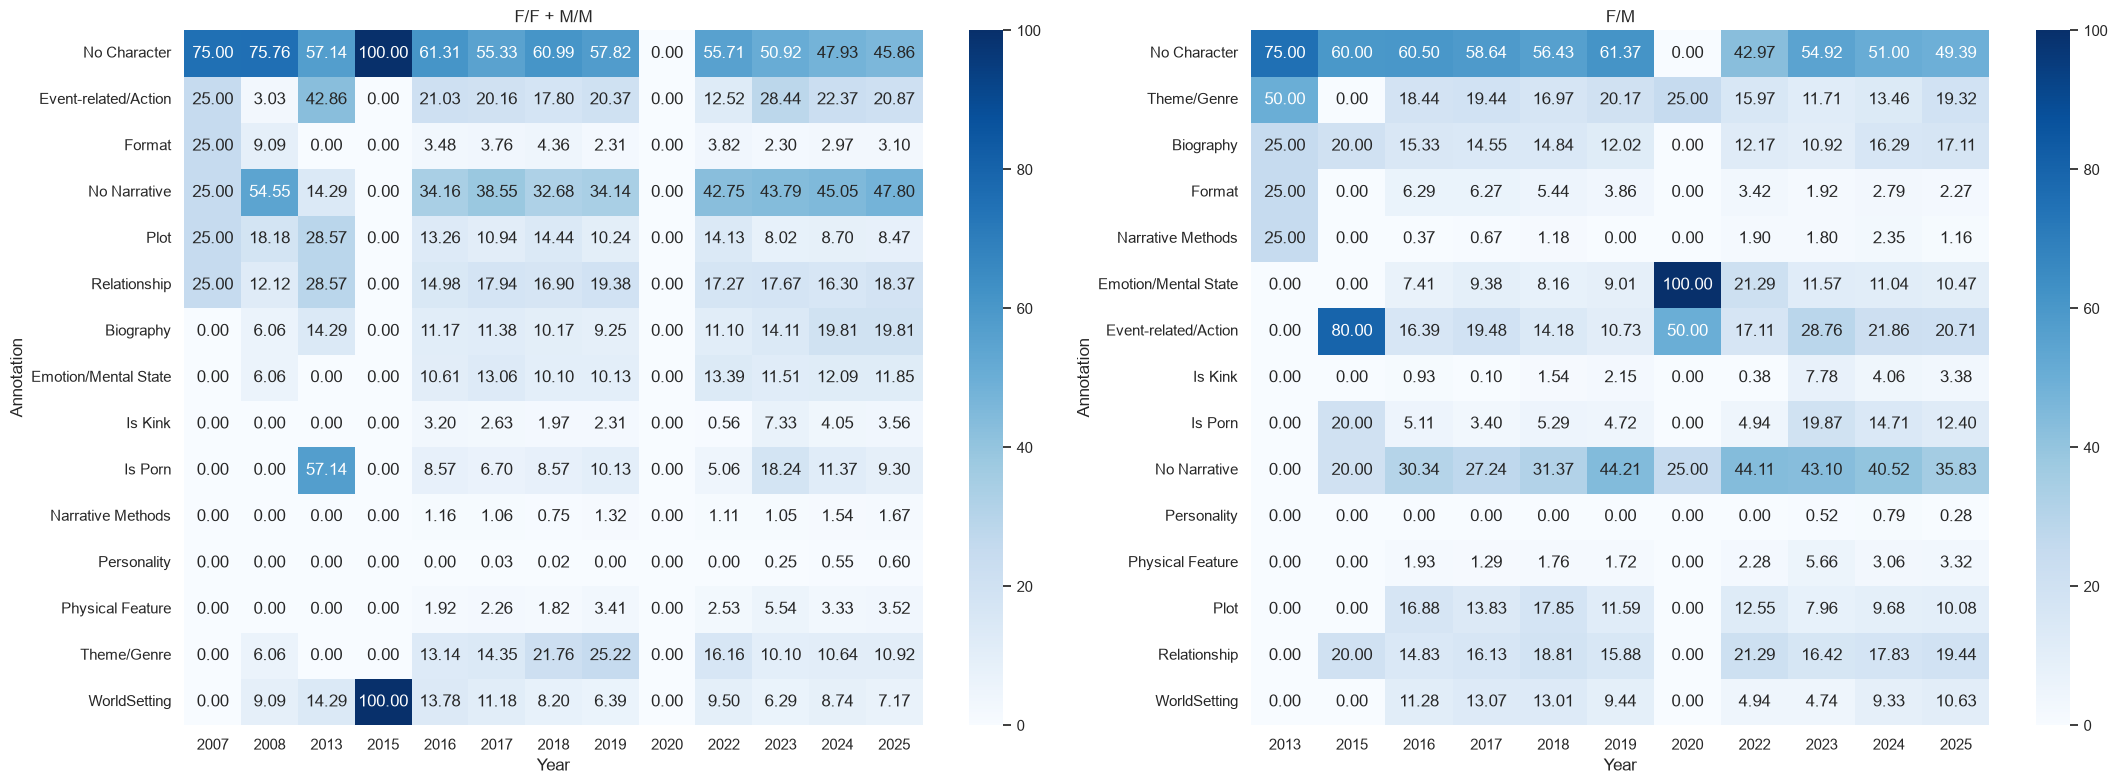

In [134]:
# Plot the heatmaps
fig, ax = plt.subplots(1, 2, figsize=(22, 8))

vmax = max(ff_mm_values.max(), fm_values.max()) # Set the max value based on the max. %

# Filtered by F/F + M/M
sns.heatmap(
    ff_mm_values,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    xticklabels=df_add_tags_ff_mm_years.columns[1:],
    yticklabels=ff_mm_labels,
    ax=ax[0]
)

ax[0].set_title("F/F + M/M")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Annotation")

# Filtered by F/M
sns.heatmap(
    fm_values,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=vmax,
    xticklabels=df_add_tags_fm_years.columns[1:],
    yticklabels=fm_labels,
    ax=ax[1]
)

ax[1].set_title("F/M")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Annotation")

plt.tight_layout()
plt.show()